In [1]:
from pathlib import Path    
import warnings    
import numpy as np    
import pandas as pd    
import matplotlib.pyplot as plt    
import seaborn as sns    
from scipy import stats    
warnings.filterwarnings("ignore")    

In [2]:
BASE_DIR = Path("..").resolve()    
PROCESSED_DIR = BASE_DIR / "data" / "processed"   
FIGURES_DIR = BASE_DIR / "figures"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
account = pd.read_csv(PROCESSED_DIR / "account_clean.csv")    
support = pd.read_csv(PROCESSED_DIR / "support_clean.csv", parse_dates=["ticket_time"])    
activity = pd.read_csv(PROCESSED_DIR / "activity_clean.csv", parse_dates=["event_time"])    

In [4]:
print(f"Loaded: account={account.shape}, support={support.shape}, activity={activity.shape}")    

Loaded: account=(400, 9), support=(918, 8), activity=(445, 3)


# 1. Multi-Source Integration & Feature Engineering

## Engineer Customer Support features (customer grain)

In [5]:
support_agg = support.groupby("user_id").agg(    
        total_tickets=("ticket_time", "count"),    
        avg_resolution_hours=("resolution_time_hours", "mean"),    
        max_resolution_hours=("resolution_time_hours", "max"),    
        open_tickets=("ticket_state", lambda s: (s == 1).sum()),    
        closed_tickets=("ticket_state", lambda s: (s == 0).sum()),    
        first_ticket_time=("ticket_time", "min"),    
        last_ticket_time=("ticket_time", "max"),    
        n_unique_channels=("channel", "nunique"),    
        n_unique_topics=("topic", "nunique"),    
).reset_index()    

In [6]:
topic_counts = (    
        pd.crosstab(support["user_id"], support["topic"])    
        .add_prefix("topic_")    
        .reset_index()    
    )    

In [7]:
channel_counts = (    
        pd.crosstab(support["user_id"], support["channel"])    
        .add_prefix("channel_")    
        .reset_index()    
    ) 

In [8]:
support_features = (    
        support_agg    
        .merge(topic_counts, on="user_id", how="left")    
        .merge(channel_counts, on="user_id", how="left")    
    )    

In [9]:
support_features

,user_id,total_tickets,avg_resolution_hours,max_resolution_hours,open_tickets,closed_tickets,first_ticket_time,last_ticket_time,n_unique_channels,n_unique_topics,topic_account,topic_billing,topic_other,topic_technical,channel_-,channel_chat,channel_email,channel_phone
0,10000,3,21.446667,23.77,2,1,2025-07-27 11:51:43.108877,2025-10-21 12:32:40.541980,2,3,1,1,1,0,0,1,2,0
1,10001,4,17.542500,26.44,3,1,2025-07-05 01:49:55.420738,2025-11-18 12:57:20.394041,2,3,0,2,1,1,0,0,1,3
2,10002,3,6.433333,10.32,2,1,2025-06-15 02:44:22.080802,2025-08-25 09:28:11.932238,2,2,0,0,2,1,0,2,1,0
3,10003,1,2.190000,2.19,1,0,2025-08-05 00:17:33.743526,2025-08-05 00:17:33.743526,1,1,0,0,1,0,1,0,0,0
4,10004,4,8.542500,10.45,2,2,2025-06-20 19:57:42.243819,2025-11-17 05:03:44.816962,4,2,0,2,0,2,1,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
362,10394,3,19.173333,23.44,2,1,2025-09-21 15:12:56.382921,2025-11-30 10:35:38.833183,2,3,1,1,1,0,0,2,1,0
363,10395,3,4.050000,5.88,2,1,2025-06-29 01:24:24.258025,2025-10-03 16:50:26.024347,2,2,0,0,2,1,0,0,1,2
364,10397,5,18.722000,27.81,2,3,2025-06-29 05:55:43.153779,2025-11-29 12:12:31.542459,2,3,1,2,0,2,0,0,1,4
365,10398,2,3.635000,4.45,2,0,2025-07-10 18:29:55.795260,2025-07-29 16:25:48.302540,1,2,0,1,0,1,0,0,2,0


### Customer Support Feature Engineering
- **Volume & Resolution Metrics:** Engineered customer-level aggregates including `total_tickets`, `avg_resolution_hours`, and `max_resolution_hours` to quantify service demand and friction.
- **Resolution State:** Separated `open_tickets` (unresolved) and `closed_tickets` (resolved) to capture pending customer frustration.
- **Interaction Breadth & Channel Preference:** Computed `n_unique_channels` and `n_unique_topics` alongside pivoted topic (`topic_technical`, `topic_billing`, etc.) and channel (`channel_chat`, `channel_phone`, etc.) counts. This allows models to identify if specific friction points (e.g., repeated billing disputes) disproportionately accelerate churn.


## Engineer User Activity features 

In [10]:
ref_date = max(activity["event_time"].max(), support["ticket_time"].max())    
activity_agg = activity.groupby("user_id").agg(    
    total_events=("event_time", "count"),    
    active_days=("event_time", lambda s: s.dt.date.nunique()),    
    first_event_time=("event_time", "min"),    
    last_event_time=("event_time", "max"),    
    n_unique_event_types=("event_type", "nunique"),    
).reset_index()    

In [11]:
activity_agg["days_since_last_activity"] = (    
        (ref_date - activity_agg["last_event_time"]).dt.total_seconds() / 86400.0    
    )    
event_type_counts = (    
        pd.crosstab(activity["user_id"], activity["event_type"])    
        .add_prefix("event_")    
        .reset_index()    
    )        
activity_features = activity_agg.merge(event_type_counts, on="user_id", how="left")    

In [12]:
activity_features

,user_id,total_events,active_days,first_event_time,last_event_time,n_unique_event_types,days_since_last_activity,event_read_article,event_share_workout,event_track_workout,event_watch_video
0,10000,3,3,2025-08-28 21:25:03.813835,2025-11-13 00:14:10.471225,2,18.908195,2,0,0,1
1,10001,1,1,2025-06-22 06:40:26.706374,2025-06-22 06:40:26.706374,1,162.639951,1,0,0,0
2,10002,1,1,2025-09-17 17:33:50.117062,2025-09-17 17:33:50.117062,1,75.186208,1,0,0,0
3,10003,1,1,2025-09-15 10:21:59.595794,2025-09-15 10:21:59.595794,1,77.486098,0,0,1,0
4,10004,4,4,2025-06-16 13:29:45.144880,2025-10-11 05:17:36.302142,2,51.697479,0,0,1,3
...,...,...,...,...,...,...,...,...,...,...,...
241,10392,2,2,2025-06-22 15:27:48.578978,2025-11-11 09:39:51.496475,1,20.515359,2,0,0,0
242,10393,3,3,2025-10-03 09:12:52.995956,2025-11-03 20:31:06.324191,2,28.063104,2,1,0,0
243,10394,1,1,2025-07-31 19:40:10.494287,2025-07-31 19:40:10.494287,1,123.098472,1,0,0,0
244,10395,2,2,2025-08-25 13:24:05.971707,2025-10-22 12:09:09.477660,2,40.411678,1,1,0,0


### User Activity Feature Engineering
- **Intensity & Temporal Spread:** Captured `total_events` (overall volume), `active_days` (distinct days of engagement), and `n_unique_event_types` (feature adoption breadth).
- **Recency Metric:** Computed `days_since_last_activity` relative to a unified benchmark date (`ref_date` = December 1, 2025, the end of the observation window). In subscription analytics (RFM framework), recency of last action is typically the most potent leading indicator of churn.
- **Feature Affinity:** Pivoted event types (`event_watch_video`, `event_share_workout`, `event_track_workout`, `event_read_article`) to discern whether engagement in specific high-value features promotes long-term retention.


## Create Unified Customer Master Dataset

In [13]:
customer_360 = (    
        account    
        .merge(support_features, on="user_id", how="left")    
        .merge(activity_features, on="user_id", how="left")    
    )    

In [14]:
count_cols = (    
        ["total_tickets", "open_tickets", "closed_tickets", "n_unique_channels", "n_unique_topics",    
         "total_events", "active_days", "n_unique_event_types"]    
        + [c for c in customer_360.columns if c.startswith(("topic_", "channel_", "event_"))]    
    )    
customer_360[count_cols] = customer_360[count_cols].fillna(0).astype(int)
customer_360["has_support_ticket"] = (customer_360["total_tickets"] > 0).astype(int)    
customer_360["has_activity"] = (customer_360["total_events"] > 0).astype(int)    

In [15]:
customer_360.head()

,customer_id,email,state,plan,plan_list_price,churn_status,user_id,is_churned,has_gdpr_request,total_tickets,...,first_event_time,last_event_time,n_unique_event_types,days_since_last_activity,event_read_article,event_share_workout,event_track_workout,event_watch_video,has_support_ticket,has_activity
0,C10000,user10000@example.com,New Jersey,enterprise,105,Y,10000,1,False,3,...,2025-08-28 21:25:03.813835,2025-11-13 00:14:10.471225,2,18.908195,2,0,0,1,1,1
1,C10001,user10001@example.net,Louisiana,basic,22,Y,10001,1,False,4,...,2025-06-22 06:40:26.706374,2025-06-22 06:40:26.706374,1,162.639951,1,0,0,0,1,1
2,C10002,user10002@example.net,Oklahoma,basic,24,NaN,10002,0,False,3,...,2025-09-17 17:33:50.117062,2025-09-17 17:33:50.117062,1,75.186208,1,0,0,0,1,1
3,C10003,user10003@example.com,Michigan,free,0,NaN,10003,0,False,1,...,2025-09-15 10:21:59.595794,2025-09-15 10:21:59.595794,1,77.486098,0,0,1,0,1,1
4,C10004,user10004@example.com,Texas,enterprise,119,NaN,10004,0,False,4,...,2025-06-16 13:29:45.144880,2025-10-11 05:17:36.302142,2,51.697479,0,0,1,3,1,1


In [16]:
output_path = PROCESSED_DIR / "fitly_customer_360_clean.csv"    
customer_360.to_csv(output_path, index=False)    

### Customer 360 Architecture & Imputation Strategy
- **Master Table Dimensions:** Successfully unified all data sources into **400 customer records across 33 columns**, strictly preserving the customer primary key grain (`user_id`).
- **Structured Missingness Handling:**
  - Left joins naturally created `NaN` values for customers without support tickets ($n = 33$) or activity logs ($n = 154$).
  - Activity and support counts were cleanly imputed with `0` (e.g., `total_events = 0`, `total_tickets = 0`).
  - **Indicator Flags:** Created binary indicators `has_support_ticket` (91.75% active) and `has_activity` (61.5% active) so downstream models can explicitly differentiate structural inactivity from missing observations.
  - **Resolution Time Imputation Note:** `avg_resolution_hours` remains `NaN` for the 33 customers without support tickets. For tree-based models (e.g., XGBoost, LightGBM), native missing value handling can be leveraged, while linear models will require median/indicator imputation.


# 2. Exploratory Data Analysis (EDA) & Statistical Testing

## 1. Univariate Graphics (Single Variable Only - 2+ Distinct Chart Types) 

### Bar Chart of Plan Tier Distribution (Categorical Univariate)    

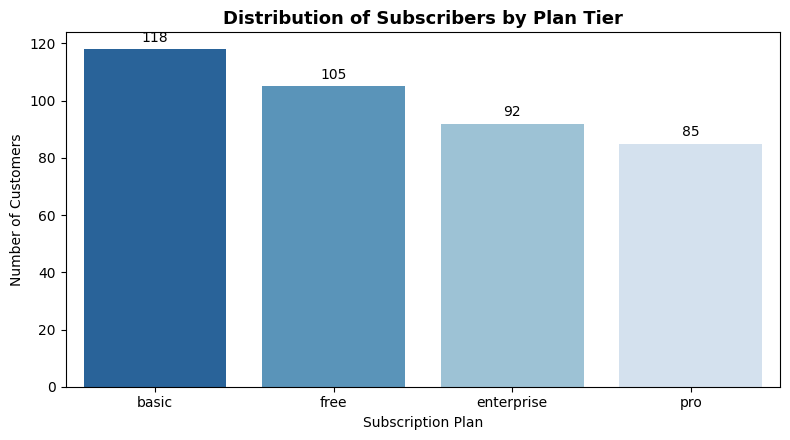

In [17]:
fig, ax = plt.subplots(figsize=(8, 4.5))

plan_order = customer_360["plan"].value_counts().index

sns.countplot(
    data=customer_360,
    x="plan",
    order=plan_order,
    ax=ax,
    palette="Blues_r"
)

ax.set_title("Distribution of Subscribers by Plan Tier", fontsize=13, fontweight="bold")
ax.set_xlabel("Subscription Plan")
ax.set_ylabel("Number of Customers")

for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "univariate_plan_distribution.png", dpi=150)
plt.show()

### Univariate Plan Distribution Analysis
- **Subscriber Composition:** Customers are well-distributed across all four tiers:
  - **Basic:** 118 subscribers (29.5%) — the largest segment.
  - **Free:** 105 subscribers (26.25%).
  - **Enterprise:** 92 subscribers (23.0%).
  - **Pro:** 85 subscribers (21.25%).
- **Business Implication:** Paid subscribers represent **73.75%** ($n = 295$) of the total user base. The sizable Free tier (26.25%) functions as a top-of-funnel acquisition tier, but requires dedicated monitoring due to distinct behavioral and monetization patterns.


## Histogram + KDE of Ticket Resolution Time

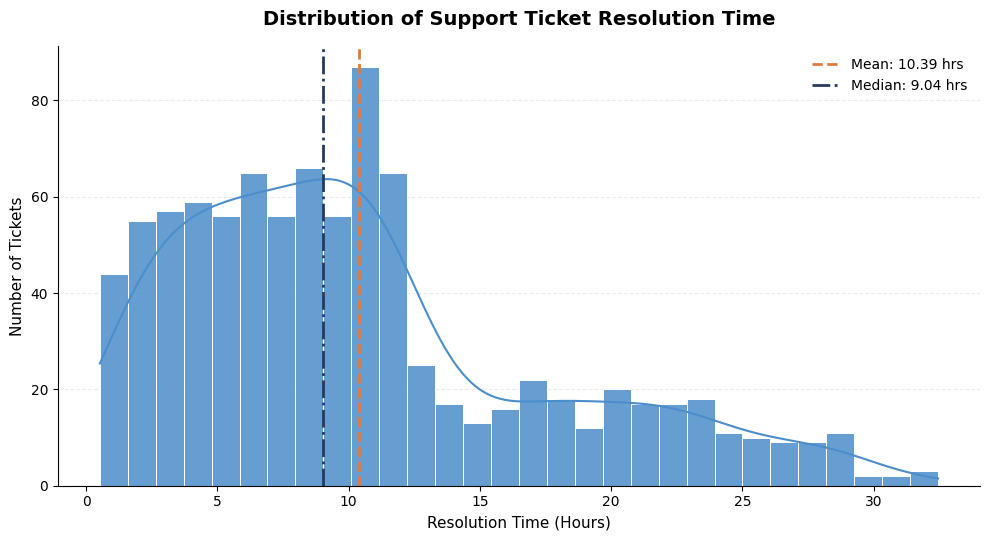

In [18]:
fig, ax = plt.subplots(figsize=(10, 5.5))

# Remove missing values
resolution = support["resolution_time_hours"].dropna()

# Calculate statistics
mean_time = resolution.mean()
median_time = resolution.median()

# Histogram
sns.histplot(
    resolution,
    bins=30,
    kde=True,
    ax=ax,
    color="#4C8DCB",
    edgecolor="white",
    linewidth=0.7,
    alpha=0.85
)

# Mean and median reference lines
ax.axvline(
    mean_time,
    color="#E07A3F",
    linestyle="--",
    linewidth=2,
    label=f"Mean: {mean_time:.2f} hrs"
)

ax.axvline(
    median_time,
    color="#263B59",
    linestyle="-.",
    linewidth=2,
    label=f"Median: {median_time:.2f} hrs"
)

# Titles and labels
ax.set_title(
    "Distribution of Support Ticket Resolution Time",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Resolution Time (Hours)", fontsize=11)
ax.set_ylabel("Number of Tickets", fontsize=11)

# Styling
ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(frameon=False, loc="upper right")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "univariate_resolution_time_hist.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Univariate Resolution Time Distribution
- **Distribution Characteristics:** The resolution time distribution is positively skewed with a primary peak around **2–4 hours** and an extended upper tail stretching to **32.5 hours**.
- **Central Tendency:** The overall mean resolution time is **10.39 hours**, noticeably higher than the median of **9.04 hours** ($+1.35$ hour skew effect), driven by complex escalations.
- **Operational Reality:** A secondary concentration of tickets clusters around the 18–24 hour mark. This reflects tickets that span across business days or require tier-2 engineering escalation, highlighting a critical window where customer frustration may compound.


# Multivariate Graphics 

## Churn Rate by Plan Tier (with 95% CI)    

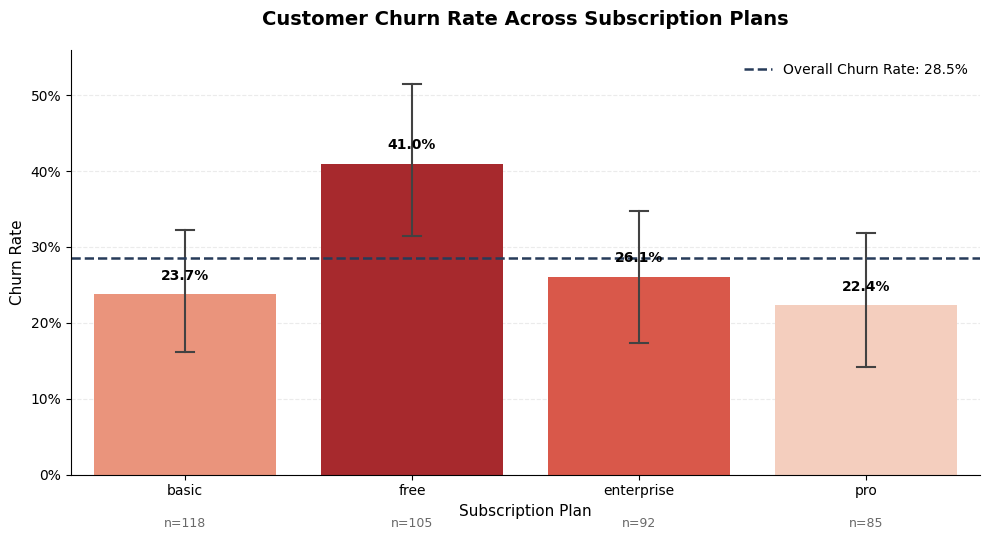

In [19]:
fig, ax = plt.subplots(figsize=(10, 5.5))

# Calculate churn statistics by plan
plan_churn = (
    customer_360.groupby("plan")
    .agg(
        churn_rate=("is_churned", "mean"),
        total_customers=("is_churned", "count"),
        churned_customers=("is_churned", "sum")
    )
    .reindex(plan_order)
    .reset_index()
)

# Overall churn rate
overall_churn = customer_360["is_churned"].mean()

# Colour gradient based on churn rate
colors = sns.color_palette(
    "Reds",
    n_colors=len(plan_churn)
)

colors = [colors[i] for i in np.argsort(
    np.argsort(plan_churn["churn_rate"])
)]

# Create bar plot
sns.barplot(
    data=customer_360,
    x="plan",
    y="is_churned",
    order=plan_order,
    errorbar=("ci", 95),
    ax=ax,
    palette=colors,
    capsize=0.08,
    err_kws={"linewidth": 1.5}
)

# Overall churn benchmark
ax.axhline(
    overall_churn,
    color="#263B59",
    linestyle="--",
    linewidth=1.8,
    label=f"Overall Churn Rate: {overall_churn:.1%}"
)

# Add churn percentage and customer count
for i, row in plan_churn.iterrows():
    ax.text(
        i,
        row["churn_rate"] + 0.015,
        f'{row["churn_rate"]:.1%}',
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

    ax.text(
        i,
        -0.10,
        f'n={row["total_customers"]:,}',
        ha="center",
        va="top",
        fontsize=9,
        color="dimgray",
        transform=ax.get_xaxis_transform()
    )

# Formatting
ax.set_title(
    "Customer Churn Rate Across Subscription Plans",
    fontsize=14,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Subscription Plan", fontsize=11)
ax.set_ylabel("Churn Rate", fontsize=11)

ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda y, _: f"{y:.0%}")
)

ax.set_ylim(0, min(1, plan_churn["churn_rate"].max() + 0.15))

ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(frameon=False, loc="upper right")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "multivariate_churn_by_plan.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Multivariate Churn Rate by Plan Tier
- **Disproportionate Free Tier Churn:** The **Free tier experiences a 41.0% churn rate** (95% CI: ~31.5% to 50.5%), substantially higher than the portfolio average benchmark (**28.5%**).
- **Paid Tier Retention Stability:** Paid plans demonstrate considerably stronger retention:
  - **Enterprise:** 26.1% churn rate.
  - **Basic:** 23.7% churn rate.
  - **Pro:** 22.4% churn rate (lowest overall churn).
- **Economic Takeaway:** Financial commitment is strongly protective against churn. Free tier users incur zero switching costs, making them highly prone to drop-off if initial onboarding fails to deliver immediate perceived value.


# Support Tickets & Activity vs. Churn    

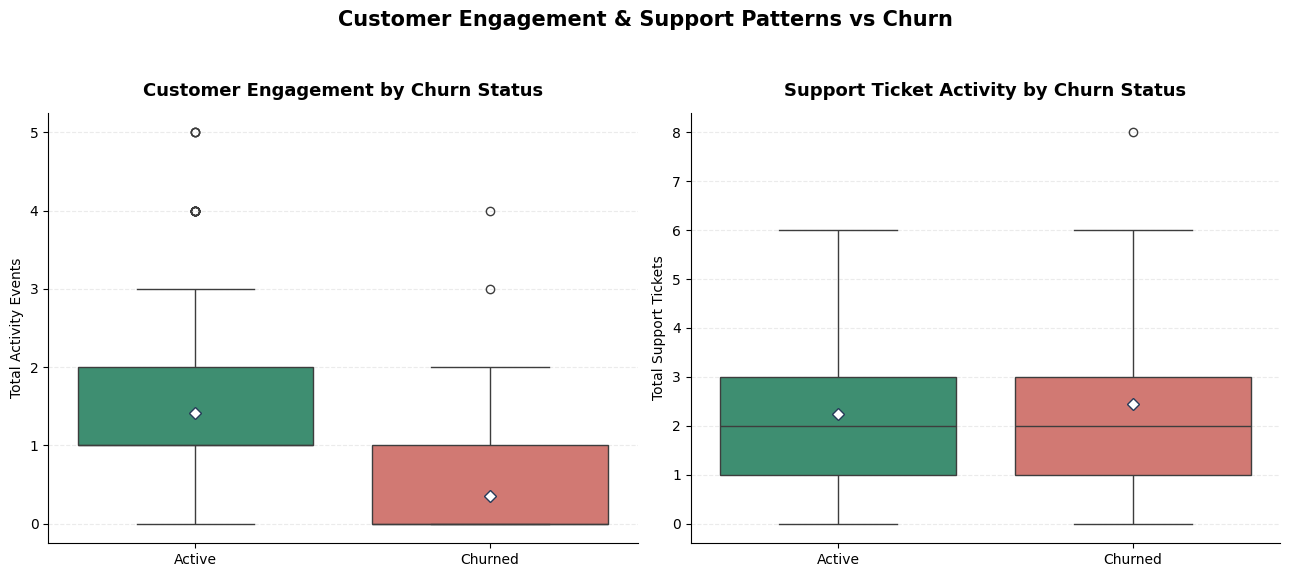

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

# Consistent colour mapping
churn_palette = {
    0: "#319B75",
    1: "#E06B64"
}

# Prepare labels
plot_data = customer_360.copy()
plot_data["Churn Status"] = plot_data["is_churned"].map({
    0: "Active",
    1: "Churned"
})

status_order = ["Active", "Churned"]

# Plot 1: Activity Events
sns.boxplot(
    data=plot_data,
    x="Churn Status",
    y="total_events",
    order=status_order,
    hue="Churn Status",
    hue_order=status_order,
    palette={"Active": "#319B75", "Churned": "#E06B64"},
    legend=False,
    showmeans=True,
    meanprops={
        "marker": "D",
        "markerfacecolor": "white",
        "markeredgecolor": "#263B59",
        "markersize": 6
    },
    ax=axes[0]
)

axes[0].set_title(
    "Customer Engagement by Churn Status",
    fontsize=13,
    fontweight="bold",
    pad=12
)

axes[0].set_xlabel("")
axes[0].set_ylabel("Total Activity Events")

# Plot 2: Support Tickets
sns.boxplot(
    data=plot_data,
    x="Churn Status",
    y="total_tickets",
    order=status_order,
    hue="Churn Status",
    hue_order=status_order,
    palette={"Active": "#319B75", "Churned": "#E06B64"},
    legend=False,
    showmeans=True,
    meanprops={
        "marker": "D",
        "markerfacecolor": "white",
        "markeredgecolor": "#263B59",
        "markersize": 6
    },
    ax=axes[1]
)

axes[1].set_title(
    "Support Ticket Activity by Churn Status",
    fontsize=13,
    fontweight="bold",
    pad=12
)

axes[1].set_xlabel("")
axes[1].set_ylabel("Total Support Tickets")

# Common styling
for ax in axes:
    ax.grid(axis="y", linestyle="--", alpha=0.25)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    "Customer Engagement & Support Patterns vs Churn",
    fontsize=15,
    fontweight="bold",
    y=1.04
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "multivariate_engagement_support_vs_churn.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Multivariate Engagement & Support Patterns vs. Churn
- **Activity Divergence (Left Boxplot):**
  - Active users exhibit consistent platform interaction, while **churned users collapse to a median of zero activity events** (and near-zero upper quartile).
  - The mean marker (diamond) confirms that active users average significantly higher engagement. Platform dormancy is a primary, observable symptom preceding customer churn.
- **The Support Ticket Volume Paradox (Right Boxplot):**
  - Median support ticket volume is identical ($	ext{median} = 2$) across both active and churned customers, with very similar interquartile ranges.
  - **Critical Analytical Insight:** Churn is **not driven by ticket volume** (how often customers reach out), but rather by **resolution duration and problem severity** (how long they wait for a resolution, as tested below).


# 3. Statistical Hypothesis 

## 3.1 Objective

The objective of this analysis is to determine whether customer characteristics, engagement levels, and support experiences are statistically associated with customer churn.

The analysis uses:
<ul>
<li>Chi-Square Test of Independence for categorical variables.</li>
<li>Mann-Whitney U Test for comparing numerical variables between active and churned customers.</li>
</ul>

### 3.2 Chi-Square Test of Independence

**Research question**: Is customer churn associated with subscription plan, support ticket presence, and platform activity?

<h4>Hypothesis Testing (Chi-Square)</h4>

<table>
    <tr>
        <th>Variable</th>
        <th>H₀ (Null)</th>
        <th>H₁ (Alternative)</th>
    </tr>
    <tr>
        <td>Subscription Plan</td>
        <td>Independent of churn</td>
        <td>Associated with churn</td>
    </tr>
    <tr>
        <td>Support Ticket</td>
        <td>Independent of churn</td>
        <td>Associated with churn</td>
    </tr>
    <tr>
        <td>Platform Activity</td>
        <td>Independent of churn</td>
        <td>Associated with churn</td>
    </tr>
</table>

**Significance Level:** α = 0.05

**Decision Rule:** p-value < 0.05 → Reject H₀; otherwise, fail to reject H₀.


In [21]:
for col in ["plan", "has_support_ticket", "has_activity"]:    
    ct = pd.crosstab(customer_360[col], customer_360["is_churned"])    
    chi2, p_val, dof, _ = stats.chi2_contingency(ct)    
    n = ct.sum().sum()    
    cramers_v = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))    
    print(f"[Chi-Square] {col} vs Churn -> chi2={chi2:.3f}, p={p_val:.4e}, Cramér's V={cramers_v:.3f}") 

[Chi-Square] plan vs Churn -> chi2=11.147, p=1.0956e-02, Cramér's V=0.167
[Chi-Square] has_support_ticket vs Churn -> chi2=2.472, p=1.1592e-01, Cramér's V=0.079
[Chi-Square] has_activity vs Churn -> chi2=77.242, p=1.5125e-18, Cramér's V=0.439


<h4>Chi-Square Results</h4>

<table>
    <tr><th>Variable</th><th>p-value</th><th>Cramér's V</th><th>Conclusion</th></tr>
    <tr><td>Plan</td><td>0.01096</td><td>0.167</td><td>Significant association</td></tr>
    <tr><td>Support Ticket</td><td>0.1592</td><td>0.079</td><td>Not significant</td></tr>
    <tr><td>Activity</td><td>1.5125e-18</td><td>0.439</td><td>Significant association</td></tr>
</table>

**Key findings:**
<ul>
<li>Subscription plan has a statistically significant association with customer churn.</li>
<li>Having a support ticket does not show a statistically significant association with churn in this test.</li>
<li>Platform activity has a statistically significant association with churn, with a considerably stronger association than the other two variables based on Cramér's V.</li>
</ul>

## 3.3 Mann-Whitney U Test

**Research question**: Do active and churned customers differ significantly in their subscription spending, support experience, and engagement levels?

Hypotheses:

For each numerical variable:
<ul>
<li>H₀: There is no statistically significant difference in the distribution of the variable between active and churned customers.</li>
<li>H₁: There is a statistically significant difference in the distribution of the variable between active and churned customers.</li>
</ul>

Variables being investigated:
<ul>
<li>Plan list price</li>
<li>Total support tickets</li>
<li>Average resolution hours</li>
<li>Total activity events</li>
<li>Active days</li>
</ul>

In [22]:
num_features = ["plan_list_price", "total_tickets", "avg_resolution_hours", "total_events", "active_days"]    
churned_grp = customer_360[customer_360["is_churned"] == 1]    
active_grp = customer_360[customer_360["is_churned"] == 0]    

In [23]:
print("\n[Mann-Whitney U Tests: Churned vs. Active]")    
for col in num_features:    
    x = churned_grp[col].dropna()    
    y = active_grp[col].dropna()    
    if len(x) > 0 and len(y) > 0:    
        u_stat, p_val = stats.mannwhitneyu(x, y, alternative="two-sided")    
        print(f"{col:25s} | Active med={y.median():.2f} | Churned med={x.median():.2f} | p={p_val:.4e}")    


[Mann-Whitney U Tests: Churned vs. Active]
plan_list_price           | Active med=27.50 | Churned med=21.00 | p=2.3609e-02
total_tickets             | Active med=2.00 | Churned med=2.00 | p=2.3263e-01
avg_resolution_hours      | Active med=6.61 | Churned med=18.63 | p=1.6556e-49
total_events              | Active med=1.00 | Churned med=0.00 | p=9.0432e-20
active_days               | Active med=1.00 | Churned med=0.00 | p=1.0221e-19


<h4>Mann-Whitney U Results</h4>

<table>
<tr>
<th>Variable</th><th>Active Median</th><th>Churned Median</th><th>p-value</th><th>Conclusion</th>
</tr>
<tr><td>Plan List Price</td><td>27.50</td><td>21.00</td><td>0.0236</td><td>Significant</td></tr>
<tr><td>Total Tickets</td><td>2.00</td><td>2.00</td><td>0.2363</td><td>Not significant</td></tr>
<tr><td>Avg. Resolution Hours</td><td>6.61</td><td>18.63</td><td>1.6556e-49</td><td>Significant</td></tr>
<tr><td>Total Events</td><td>1.00</td><td>0.00</td><td>9.0432e-20</td><td>Significant</td></tr>
<tr><td>Active Days</td><td>1.00</td><td>0.00</td><td>1.0221e-19</td><td>Significant</td></tr>
</table>

**Key findings:**
<ul>
<li>Churned customers have a lower median plan list price.</li>
<li>Average support resolution time is considerably higher among churned customers.</li>
<li>Active customers have higher median activity events and active days.</li>
<li>Total support ticket counts do not show a statistically significant difference between the two groups.</li>
</ul>